# Bout discretization — variant comparison bench

A single notebook to compare **every way of running the bout pipeline** and see, from the plots, which works best. Each *variant* is a combination of:

- **smoothing**: none / gaussian-only (positions) / speed-only / both — **applied only to bout detection**; every trajectory/arrow below is plotted from the **raw** positions;
- **heading source**: `displacement` (onset-to-onset — net travel to the next bout, the **pipeline** method), `displacement_peak` (the old peak-to-peak variant, kept for comparison), or `bodyaxis` (the tracked `f_ori`);
- **onset mode**: `trough` (bout start) or `lead` (Le Goc 80 ms before peak).

For each variant we render the same four plots — **speed trace, trajectory (by order), heading arrows (coloured by speed), and the δθ histogram** — plus a final summary table ranking all variants.

> Note: the **speed trace only depends on smoothing** (detection runs on speed). Trajectories and arrows are always drawn from the **raw** positions — smoothing is a detection aid, never a display transform. Because `displacement` heading is onset-to-onset on the raw positions, the **onset mode also shapes the heading** (it no longer affects `dt`/detection only).

## 1. Setup, constants, helpers

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

FPS = 30.0
DISH_RADIUS_MM = 50.0
POS_SIGMA = 2.0                 # Gaussian position smoothing (frames)
SPEED_WIN = 3                  # speed rolling-mean window (frames)
BOUT_LEAD_FR = round(0.08 * FPS)   # 'lead' onset = 80 ms before peak (=2)
REFRACTORY_FR = round(0.40 * FPS)  # min frames between bouts (=12)
DISP_WIN_FR = round(0.50 * FPS)    # +/- displacement window (=15)
DISP_MIN_MM, DISP_MAX_MM = 0.3, 18.0
FORWARD_THRESH_DEG = 10.0
K = 1.0                        # speed-threshold factor (mean + K*std)

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
INPUT_DIR = ROOT / "data" / "data" / "df_transformed"
ROI_PATH = ROOT / "data" / "data" / "ROIdef.csv"
csvs = sorted(INPUT_DIR.glob("*_transformed_abs.csv"))
roi = pd.read_csv(ROI_PATH, header=None,
                  names=["xoff", "yoff", "diameter", "x", "y", "radius"])
scale_by_fish = (DISH_RADIUS_MM / roi["radius"]).to_dict()
print(len(csvs), "fish files")

15 fish files


In [ ]:
def wrap_pi(a):
    return (np.asarray(a) + np.pi) % (2 * np.pi) - np.pi


def prep_xy(seg, prefix, scale, smooth_pos):
    x = seg[f"{prefix}_x"].to_numpy(dtype=float) * scale
    y = seg[f"{prefix}_y"].to_numpy(dtype=float) * scale
    if smooth_pos and len(x) > 3:
        x = gaussian_filter1d(x, POS_SIGMA); y = gaussian_filter1d(y, POS_SIGMA)
    return x, y


def speed_of(x, y, smooth_speed):
    v = np.concatenate([[0.0], np.hypot(np.diff(x), np.diff(y))]) * FPS
    if smooth_speed:
        v = pd.Series(v).rolling(SPEED_WIN, center=True, min_periods=1).mean().to_numpy()
    return v


def _trough(v, p):
    i = p
    while i > 0 and v[i - 1] <= v[i]:
        i -= 1
    return i


def detect(x, y, v, onset):
    n = len(x)
    if n < 2 * DISP_WIN_FR + 2:
        return np.array([], int), np.array([], int)
    thr = np.nanmean(v) + K * np.nanstd(v)
    peaks, _ = find_peaks(v, height=thr, distance=REFRACTORY_FR)
    if onset == "trough":
        onsets = np.array([_trough(v, p) for p in peaks], dtype=int)
    else:
        onsets = np.clip(peaks - BOUT_LEAD_FR, 0, n - 1)
    keep = []
    for o, p in zip(onsets, peaks):
        a, b = max(o - DISP_WIN_FR, 0), min(o + DISP_WIN_FR, n - 1)
        if DISP_MIN_MM <= np.hypot(x[b] - x[a], y[b] - y[a]) <= DISP_MAX_MM:
            keep.append((o, p))
    if not keep:
        return np.array([], int), np.array([], int)
    keep.sort()
    on = np.array([k[0] for k in keep]); pk = np.array([k[1] for k in keep])
    _, idx = np.unique(on, return_index=True)
    return on[idx], pk[idx]


def bout_arrays(x, y, v, onsets, peaks, ori, heading):
    """Per-bout heading theta, reorientation dtheta, and bout speed. x, y are the
    RAW positions (smoothing is only a detection aid, so heading is measured raw).

    heading='bodyaxis'          -> theta = tracked f_ori at onset (one per bout);
    heading='displacement'      -> theta = dir(onset_i -> onset_{i+1}): the net
                                   travel to the NEXT bout. PIPELINE method
                                   (onset-to-onset, after discretization), so each
                                   heading points where the fish actually goes until
                                   the next bout;
    heading='displacement_peak' -> theta = dir(peak_i -> peak_{i+1}): the old
                                   peak-anchored variant, kept only for comparison.
    """
    m = len(onsets)
    theta = np.full(m, np.nan)
    if heading == "bodyaxis":
        theta[:] = ori[onsets]
    elif heading == "displacement_peak":
        if m >= 2:
            theta[:m - 1] = np.arctan2(np.diff(y[peaks]), np.diff(x[peaks]))
    elif m >= 2:  # 'displacement' = onset-to-onset (pipeline)
        theta[:m - 1] = np.arctan2(np.diff(y[onsets]), np.diff(x[onsets]))
    dtheta = np.full(m, np.nan)
    dtheta[1:] = wrap_pi(theta[1:] - theta[:-1])
    bout_speed = v[peaks]
    return theta, dtheta, bout_speed


def block_for_plot(seg, prefix, scale, opts):
    # smoothed (per-variant) positions -> DETECTION only: onset/peak FRAMES + speed
    xd, yd = prep_xy(seg, prefix, scale, opts["smooth_pos"])
    v = speed_of(xd, yd, opts["smooth_speed"])
    onsets, peaks = detect(xd, yd, v, opts["onset"])
    # RAW positions -> what we PLOT and measure heading from (smoothing never bends them)
    xr, yr = prep_xy(seg, prefix, scale, False)
    ori = seg[f"{prefix}_ori"].to_numpy(dtype=float)
    theta, dtheta, bs = bout_arrays(xr, yr, v, onsets, peaks, ori, opts["heading"])
    return dict(x=xr, y=yr, v=v, onsets=onsets, peaks=peaks, theta=theta,
                dtheta=dtheta, bout_speed=bs)


def kin_for_fish(df, prefix, scale, opts):
    """All bouts of one fish (split at gaps): signed dtheta(deg), dt(s).
    Detection uses the variant's smoothing; heading is measured on RAW positions."""
    df = df.reset_index(drop=True)
    has = df[f"{prefix}_x"].notna() & df[f"{prefix}_y"].notna()
    segid = ((~has) & has.shift(fill_value=False)).cumsum()
    SDTH, DT = [], []
    for _, idx in df.assign(_s=segid).groupby("_s").groups.items():
        sub = df.loc[idx]; sub = sub[has.loc[idx]]
        if len(sub) < 2 * DISP_WIN_FR + 2:
            continue
        xd, yd = prep_xy(sub, prefix, scale, opts["smooth_pos"])   # detection
        v = speed_of(xd, yd, opts["smooth_speed"])
        onsets, peaks = detect(xd, yd, v, opts["onset"])
        if len(onsets) < 3:
            continue
        xr, yr = prep_xy(sub, prefix, scale, False)                # raw -> heading
        ori = sub[f"{prefix}_ori"].to_numpy(dtype=float)
        frames = sub["frame"].to_numpy()
        theta, dtheta, _ = bout_arrays(xr, yr, v, onsets, peaks, ori, opts["heading"])
        dt = np.full(len(onsets), np.nan); dt[:-1] = np.diff(frames[onsets]) / FPS
        msk = np.isfinite(dtheta)
        SDTH += list(np.degrees(dtheta[msk]))
        DT += list(dt[np.isfinite(dt)])
    return np.array(SDTH), np.array(DT)


print("helpers defined.")

In [3]:
# example fish + one stimulus block used for the per-variant plots
df0 = pd.read_csv(csvs[0])
prefix0 = next(re.match(r"(f\d+)_x$", c).group(1) for c in df0.columns if re.match(r"(f\d+)_x$", c))
scale0 = scale_by_fish[0]
blk = (df0["stimulus"] != df0["stimulus"].shift()).cumsum()
cand = df0.assign(_b=blk).groupby("_b").filter(
    lambda g: g["stimulus"].iloc[0].startswith("CLsemi") and len(g) > 600)
seg0 = cand[cand["_b"] == cand["_b"].iloc[0]].reset_index(drop=True)
print("example block:", seg0["stimulus"].iloc[0], len(seg0), "frames")

example block: CLsemi1800_g4-0_s3.5-3.5 1800 frames


## 2. Speed preprocessing — raw vs smoothing variants (heading-independent)

The four ways to preprocess the speed signal, on the same block. Watch the **baseline between bouts** and the **number of detected bouts**: raw integer-pixel jitter produces a noisy baseline and many spurious detections; smoothing flattens it.

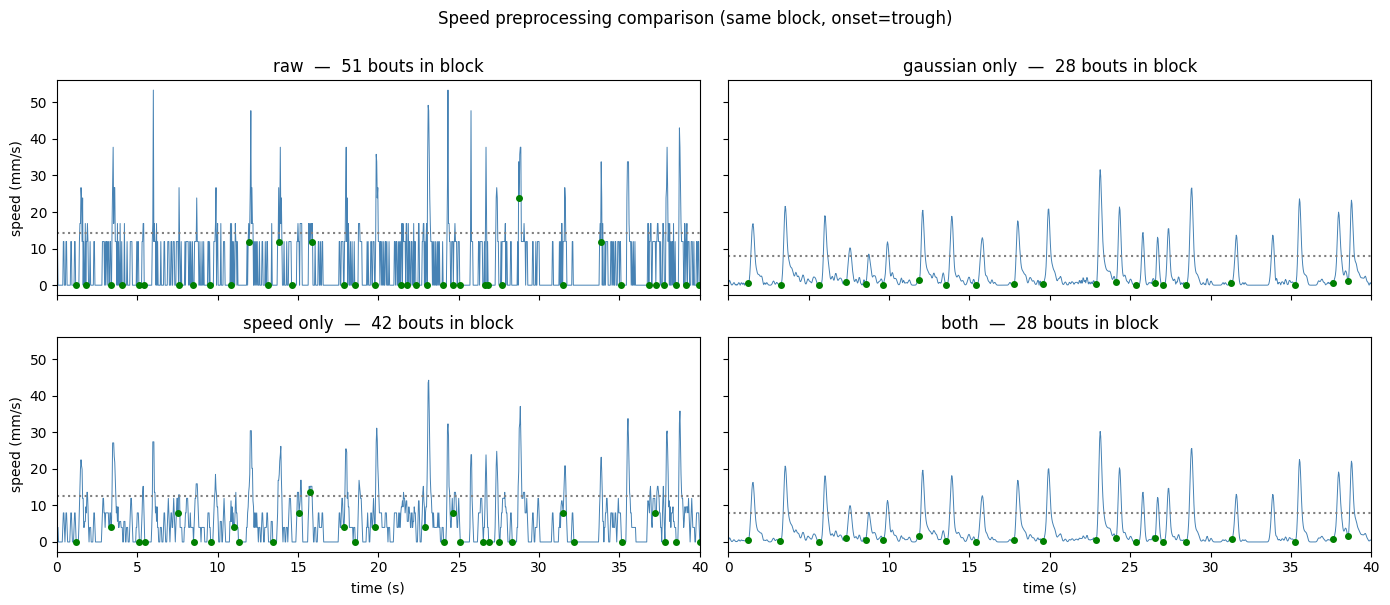

In [4]:
smoothing_variants = [("raw", False, False), ("gaussian only", True, False),
                      ("speed only", False, True), ("both", True, True)]
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, (nm, sp, ss) in zip(axes.flat, smoothing_variants):
    x, y = prep_xy(seg0, prefix0, scale0, sp)
    v = speed_of(x, y, ss)
    on, pk = detect(x, y, v, "trough")
    tt = np.arange(len(v)) / FPS
    ax.plot(tt, v, lw=0.7, color="steelblue")
    ax.axhline(np.nanmean(v) + K * np.nanstd(v), color="gray", ls=":")
    ax.plot(on / FPS, v[on], "o", color="green", ms=4)
    ax.set_xlim(0, 40); ax.set_title(f"{nm}  —  {len(on)} bouts in block")
axes[1, 0].set_xlabel("time (s)"); axes[1, 1].set_xlabel("time (s)")
axes[0, 0].set_ylabel("speed (mm/s)"); axes[1, 0].set_ylabel("speed (mm/s)")
plt.suptitle("Speed preprocessing comparison (same block, onset=trough)", y=1.0)
plt.tight_layout(); plt.show()

### 2b. Heading source head-to-head — onset→onset vs peak→peak vs body axis (the key visual)

The single cleanest "which heading is right?" test: the **same block**, with arrows from three headings — **displacement onset→onset** (the pipeline method), the old **displacement peak→peak**, and the **tracked body axis (`f_ori`)** — all drawn over the **raw (unsmoothed)** path (smoothing was used only to detect the bouts). A correct heading makes every arrow run **along the path**; the body-axis side shows arrows that **flip 180°** and point back along the trajectory. Compare onset→onset vs peak→peak to see how much the anchor choice perturbs the inferred heading (onset→onset guarantees each arrow points to the next bout, but is more sensitive to rest-point position noise).

In [ ]:
# Cleanest single test of "which heading is right": same block, both-smoothed,
# three headings side by side -- displacement onset->onset (PIPELINE), the old
# displacement peak->peak, and body axis (f_ori) -- arrows coloured by speed.
# Good heading -> arrows run ALONG the path. Body axis -> some arrows flip 180 deg.
# onset->onset vs peak->peak shows how much the anchor choice perturbs the heading.
opts_on = dict(smooth_pos=True, smooth_speed=True, heading="displacement", onset="trough")
opts_pk = dict(smooth_pos=True, smooth_speed=True, heading="displacement_peak", onset="trough")
opts_b = dict(smooth_pos=True, smooth_speed=True, heading="bodyaxis", onset="trough")

panels = [("displacement onset->onset (pipeline)", opts_on),
          ("displacement peak->peak (old)", opts_pk),
          ("body axis (f_ori)", opts_b)]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
q = None
for a, (title, opts) in zip(axes, panels):
    b = block_for_plot(seg0, prefix0, scale0, opts)
    x, y, on, theta, bs = b["x"], b["y"], b["onsets"], b["theta"], b["bout_speed"]
    a.plot(x, y, lw=0.5, color="lightgray")
    msk = np.isfinite(theta); L = 3.0
    q = a.quiver(x[on][msk], y[on][msk], L * np.cos(theta[msk]), L * np.sin(theta[msk]),
                 bs[msk], angles="xy", scale_units="xy", scale=1, cmap="viridis", width=0.006)
    a.set_aspect("equal"); a.set_xlabel("x (mm)"); a.set_ylabel("y (mm)")
    a.set_title(f"heading = {title}")
fig.colorbar(q, ax=axes.ravel().tolist(), label="bout speed (mm/s)", shrink=0.7)
plt.suptitle("Heading head-to-head (both-smoothed, same block) — arrows should follow the path", y=1.02)
plt.show()

## 3. Full plot set for every variant

Edit `VARIANTS` to add/remove combinations. Each variant renders 4 panels: **speed trace** (block), **trajectory by order** (block), **heading arrows coloured by speed** (block), and the **δθ histogram** (all of fish 0). The default grid is **4 smoothing × 3 heading × 2 onset = 24 variants**. (That's a lot of figures to scroll — trim `VARIANTS` if you only want a subset; e.g. keep just `heading in {"displacement", "displacement_peak"}` with `smooth_pos and smooth_speed`.)

In [ ]:
HEADINGS = [("displacement onset->onset (pipeline)", "displacement"),
            ("displacement peak->peak (old)", "displacement_peak"),
            ("body axis (f_ori)", "bodyaxis")]
ONSETS = ["trough", "lead"]
VARIANTS = []
for (snm, sp, ss) in smoothing_variants:
    for (hnm, hd) in HEADINGS:
        for onset in ONSETS:
            VARIANTS.append(dict(name=f"{snm}  |  {hnm}  |  onset={onset}",
                                 smooth_pos=sp, smooth_speed=ss, heading=hd, onset=onset))
print(len(VARIANTS), "variants  (4 smoothing x 3 heading x 2 onset)")

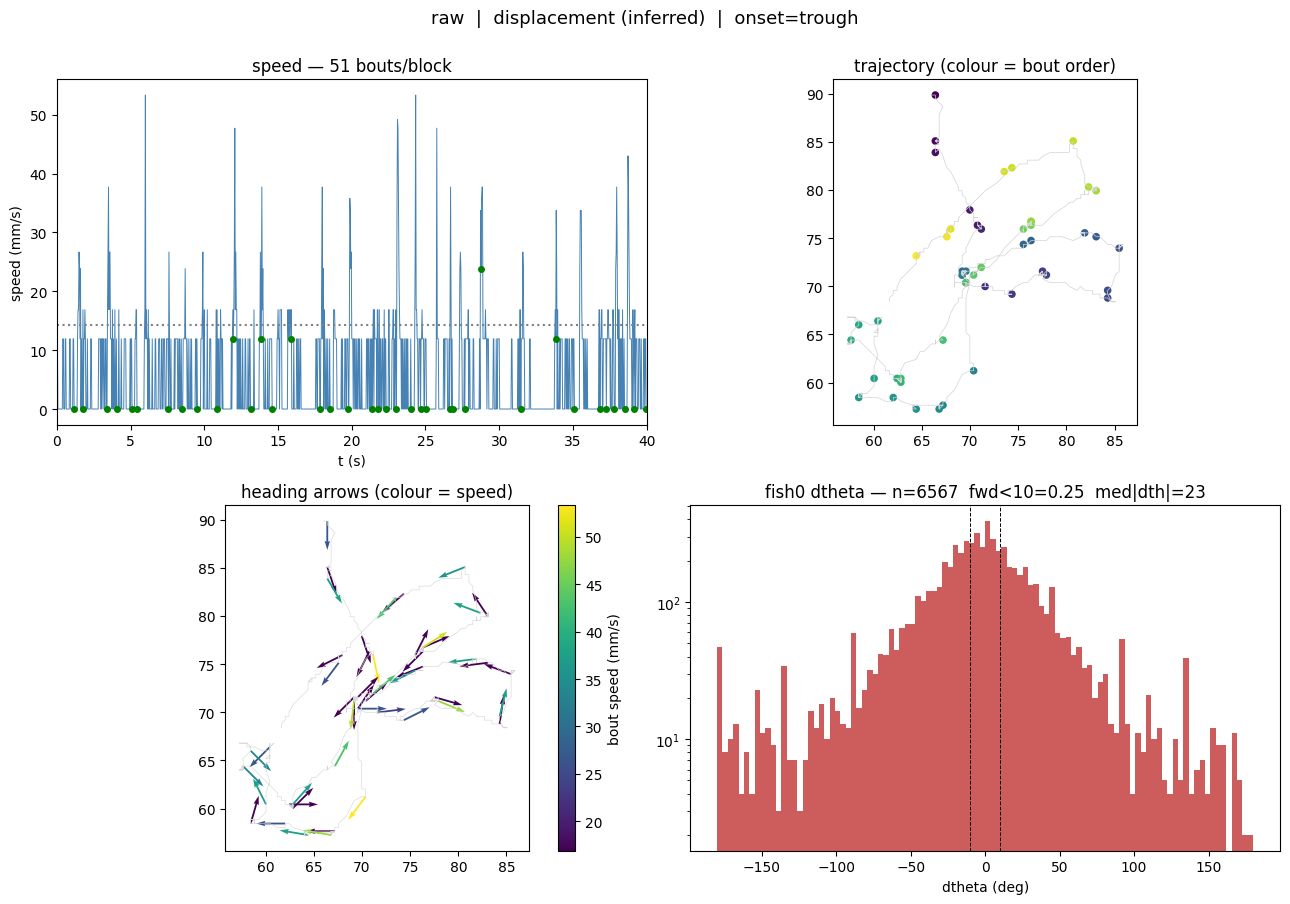

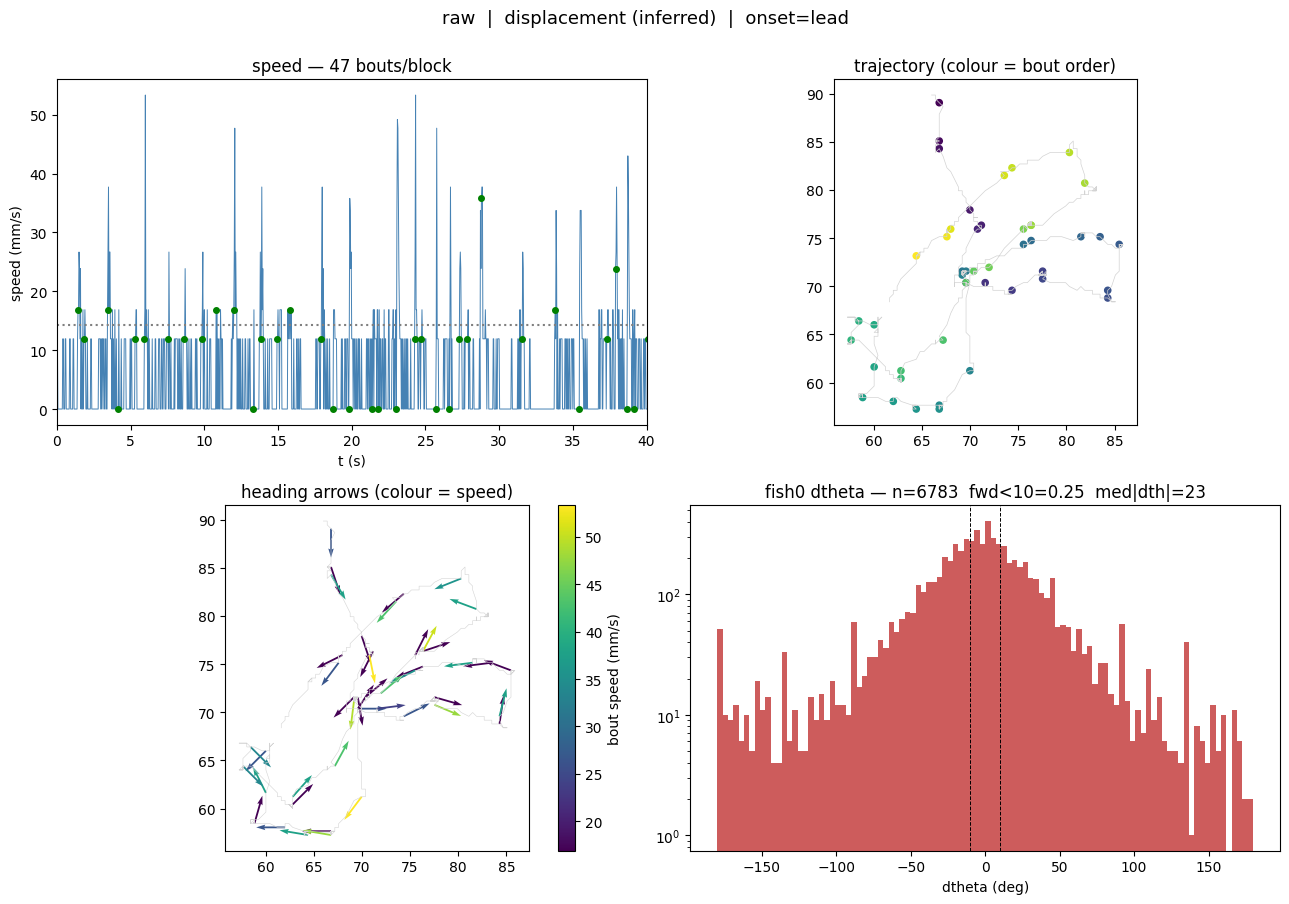

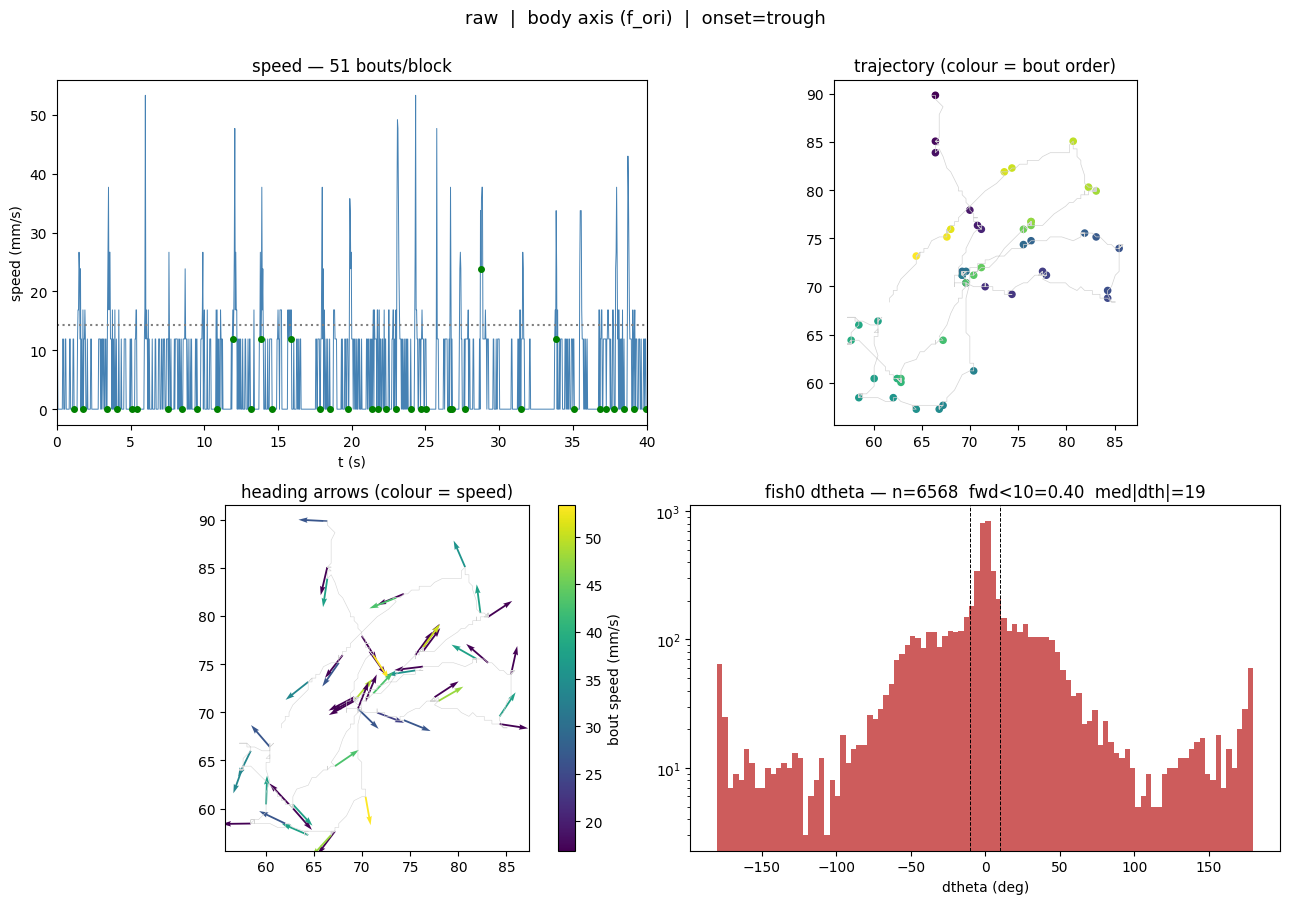

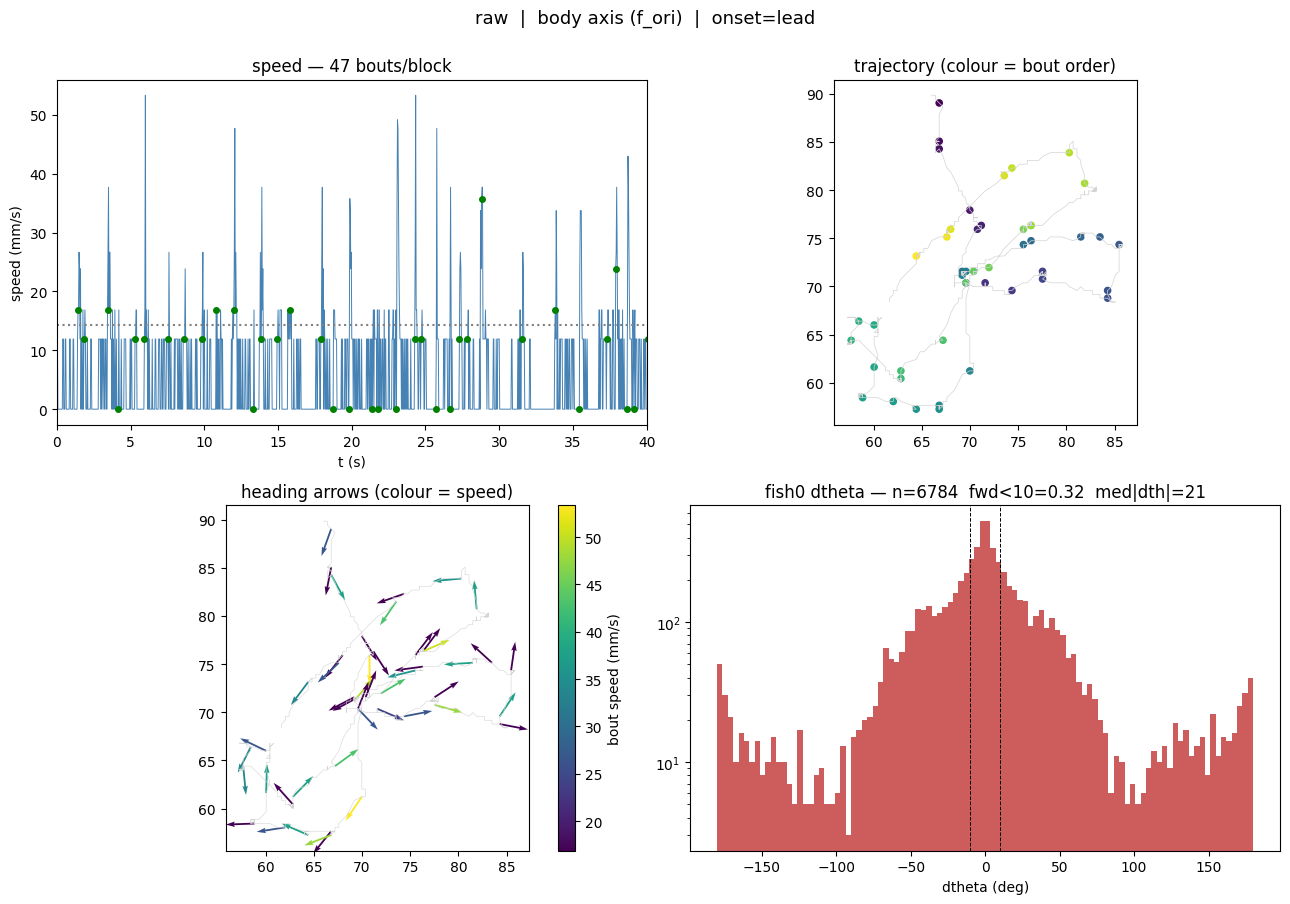

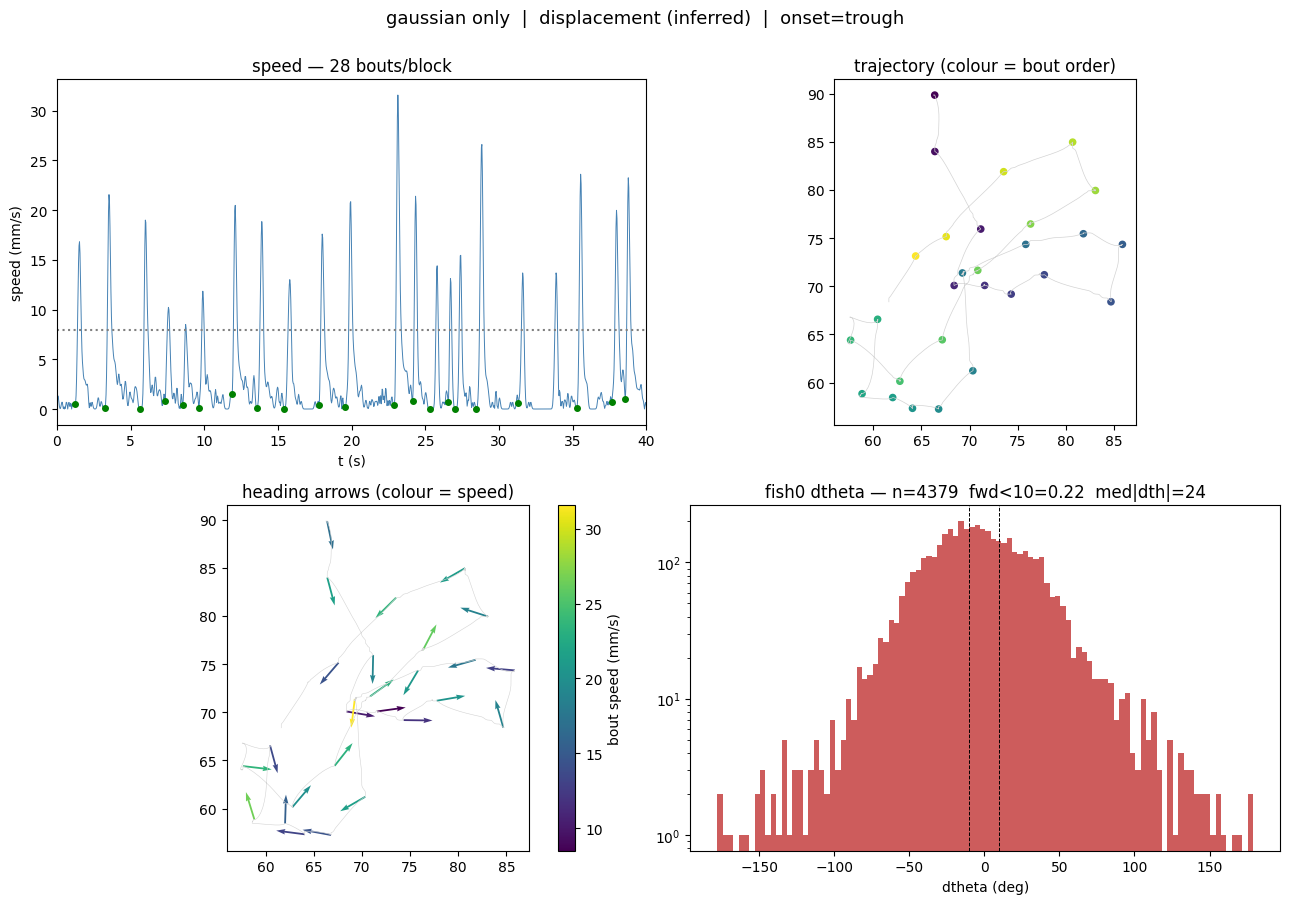

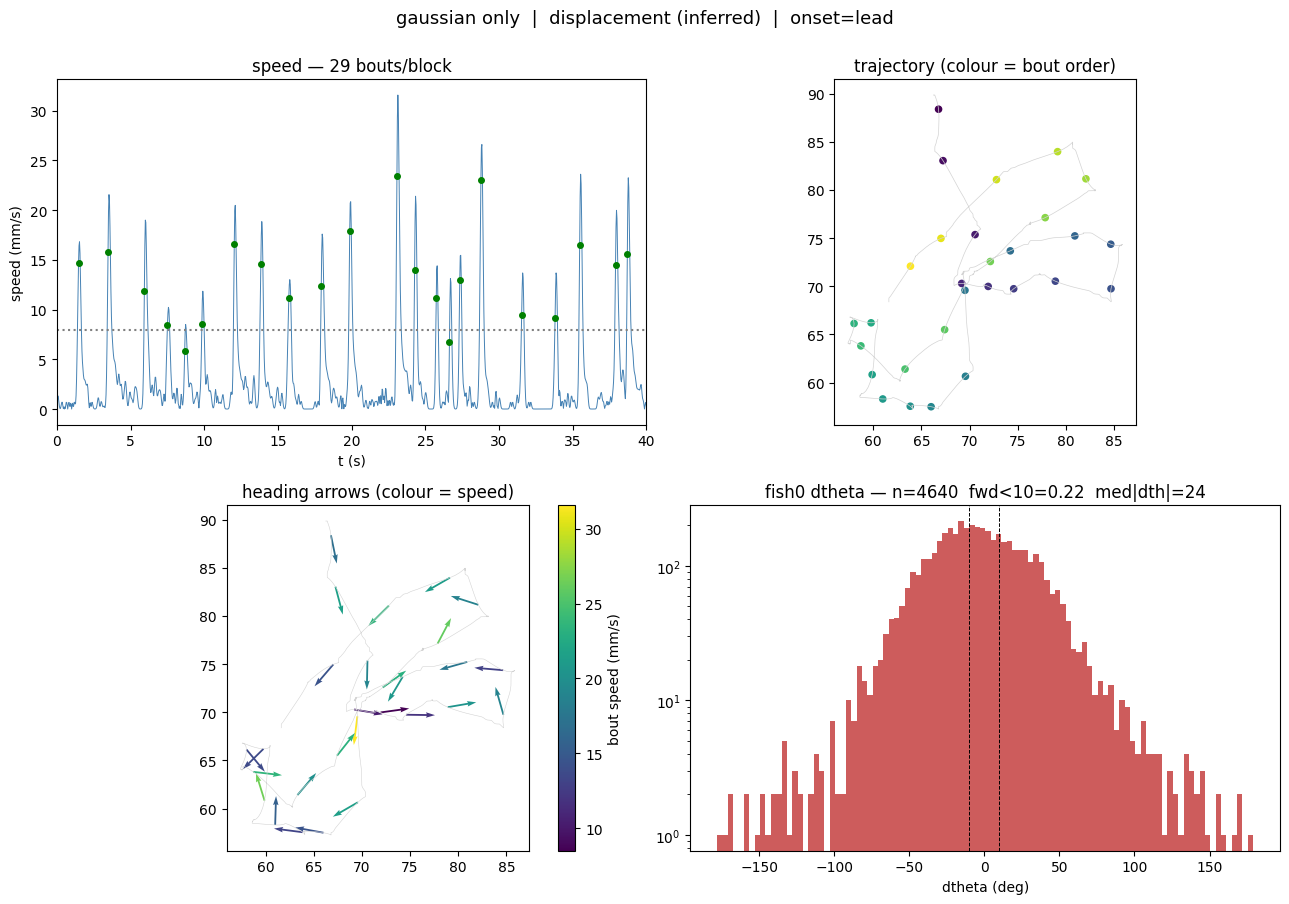

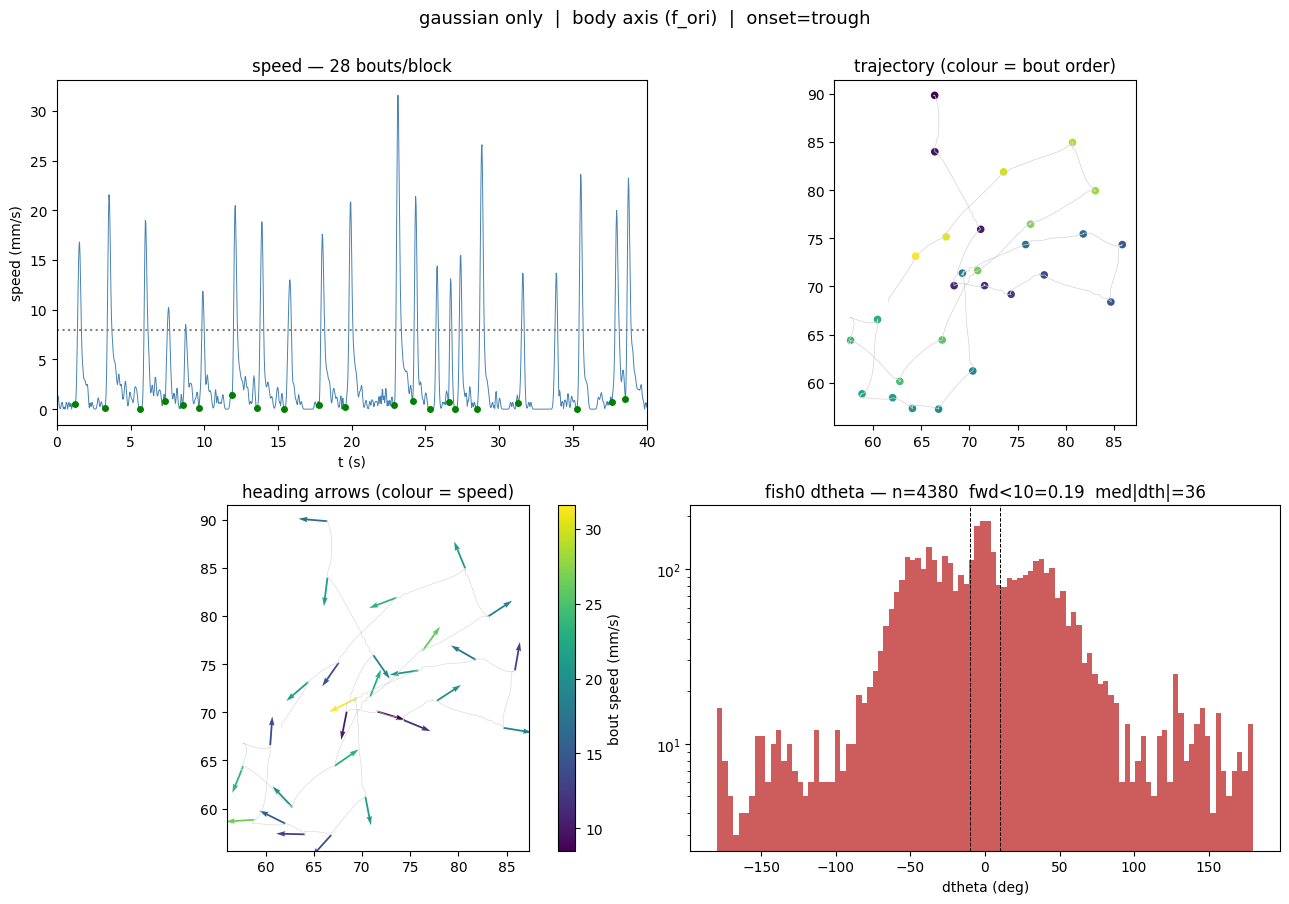

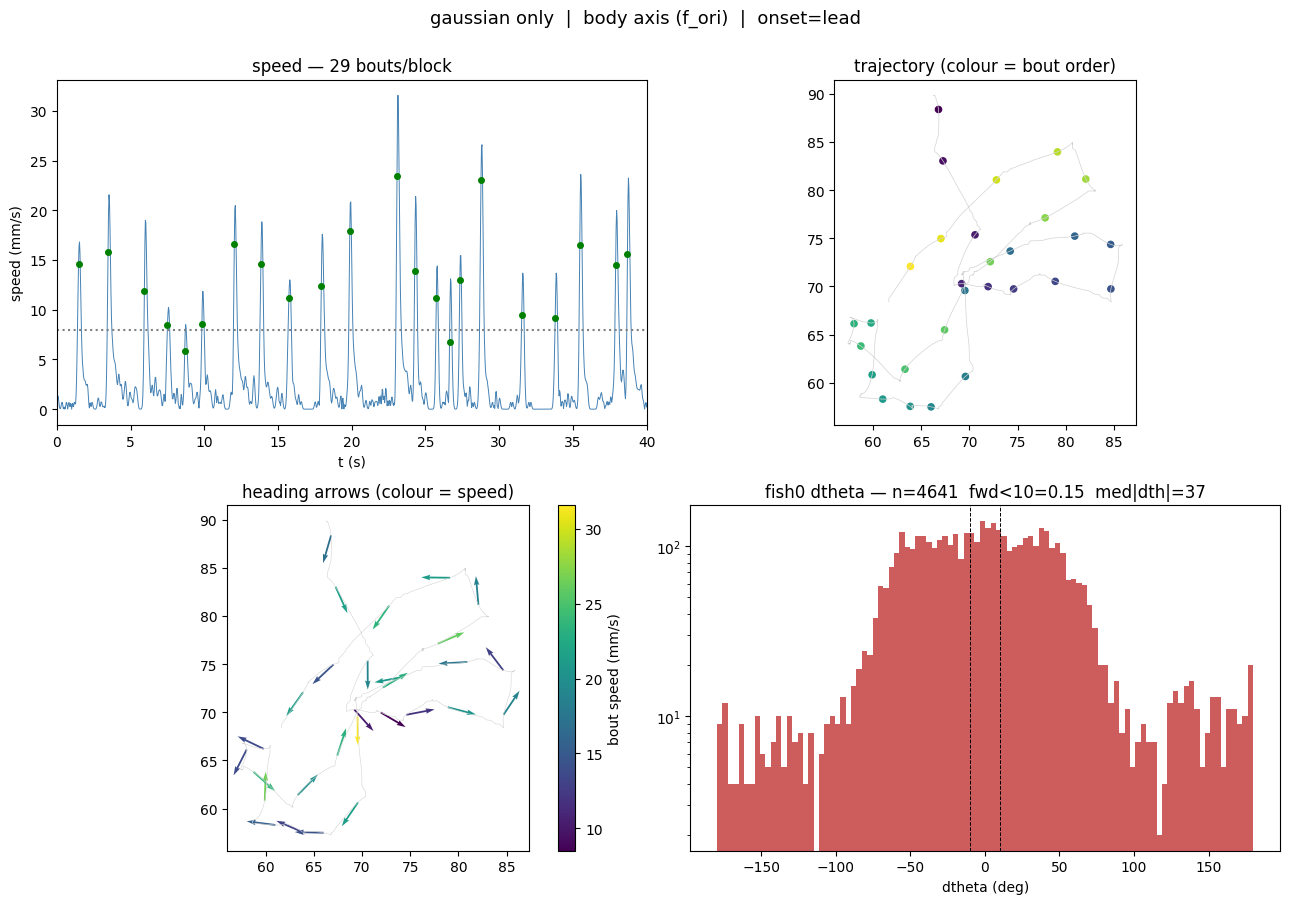

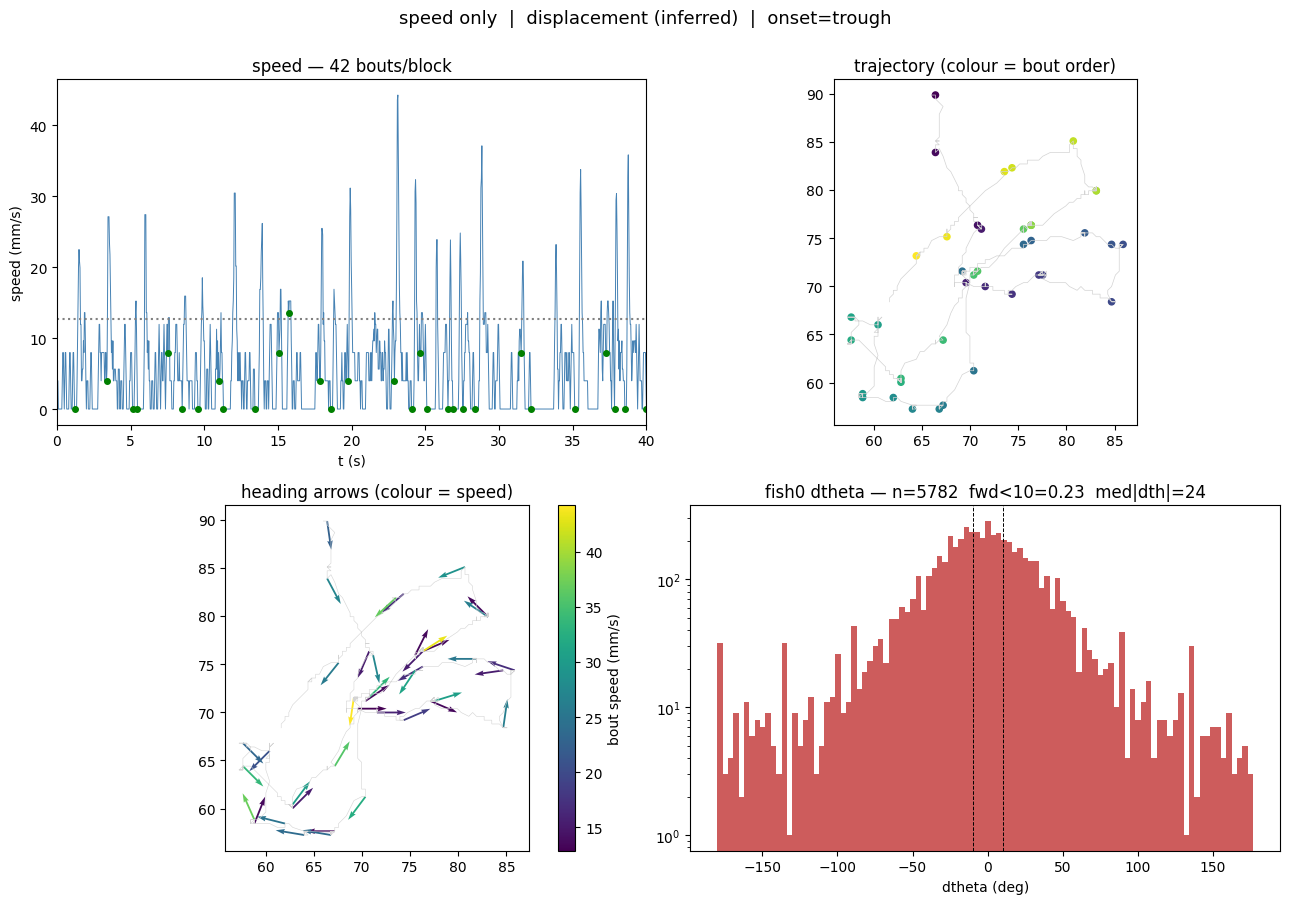

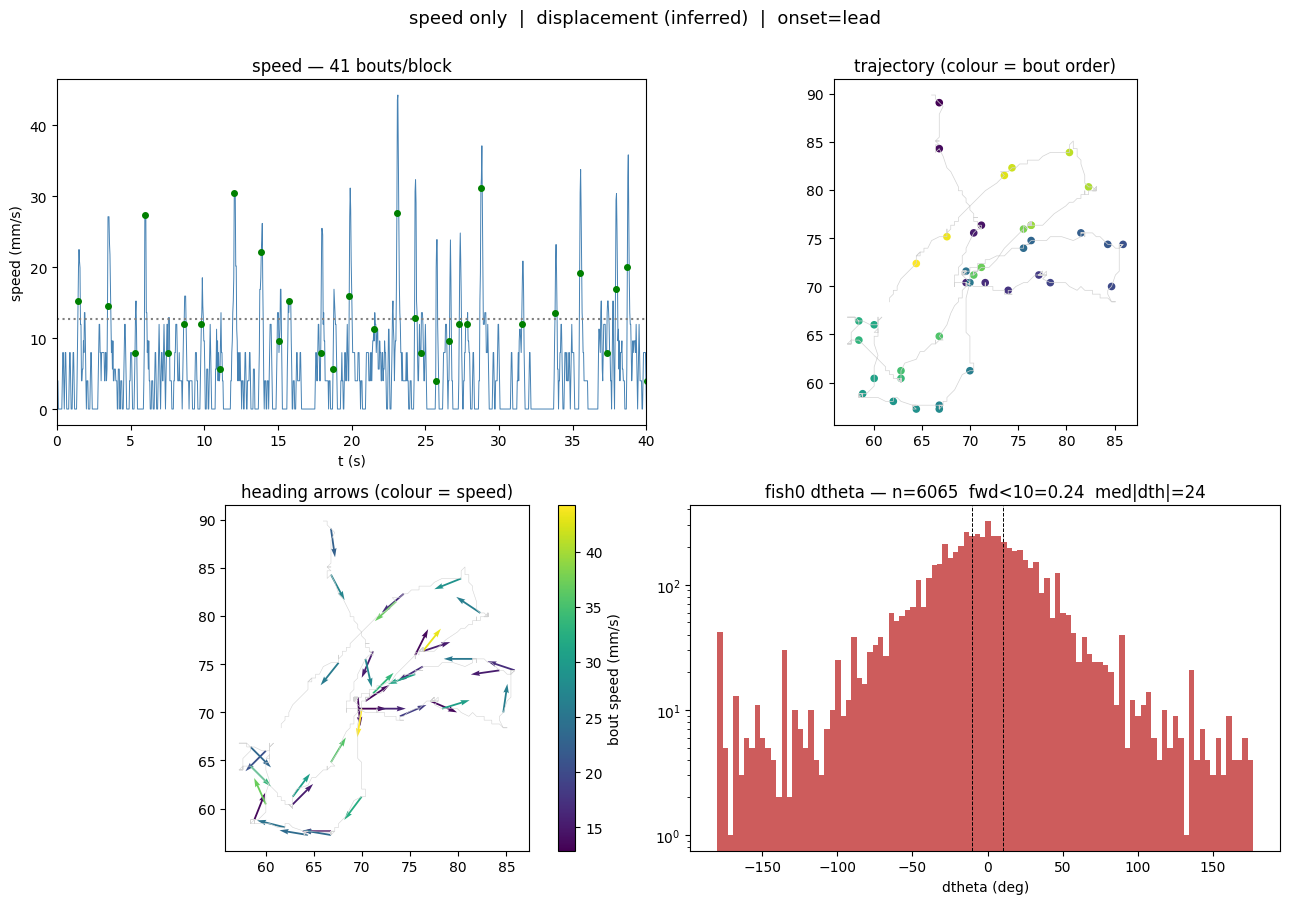

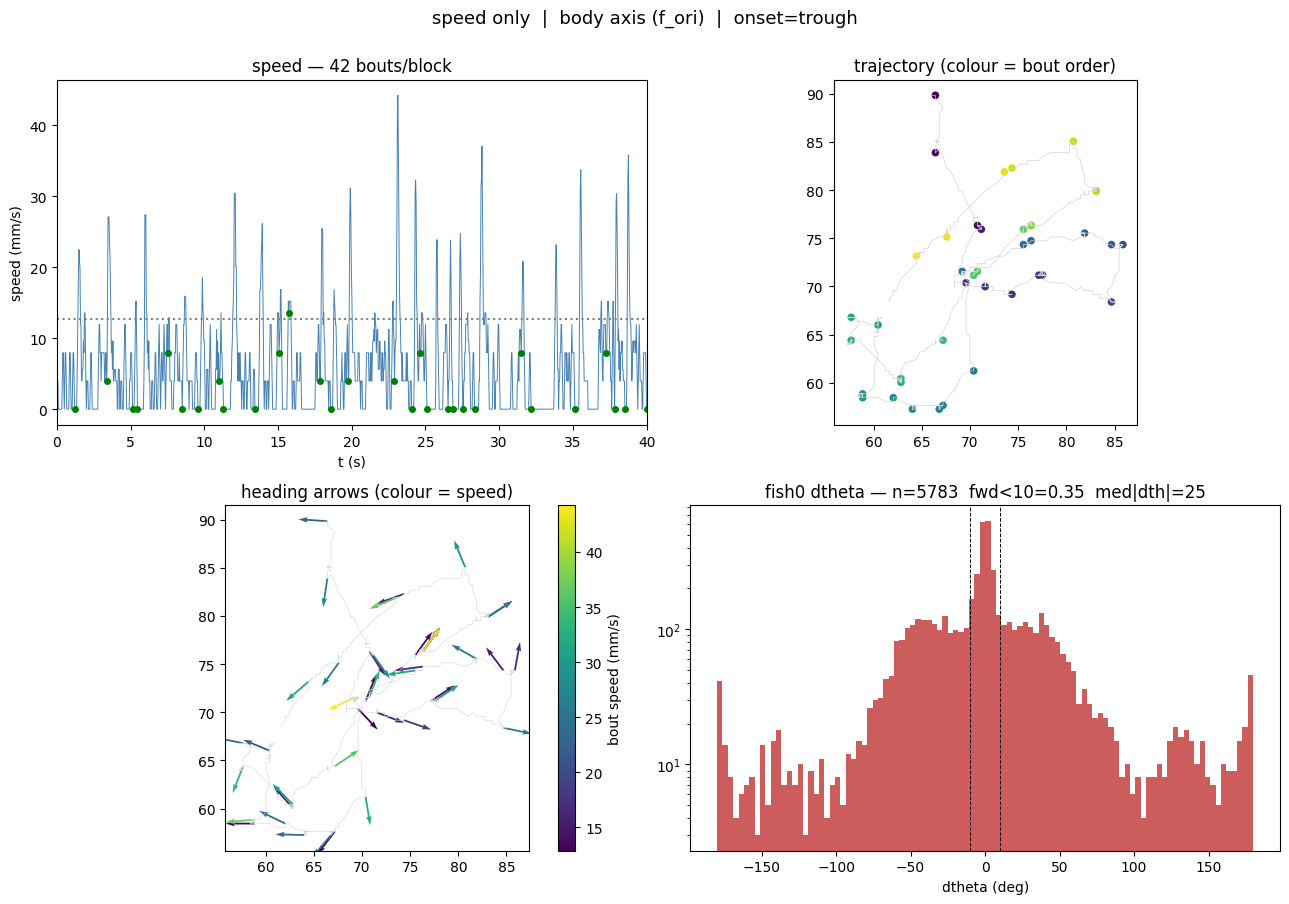

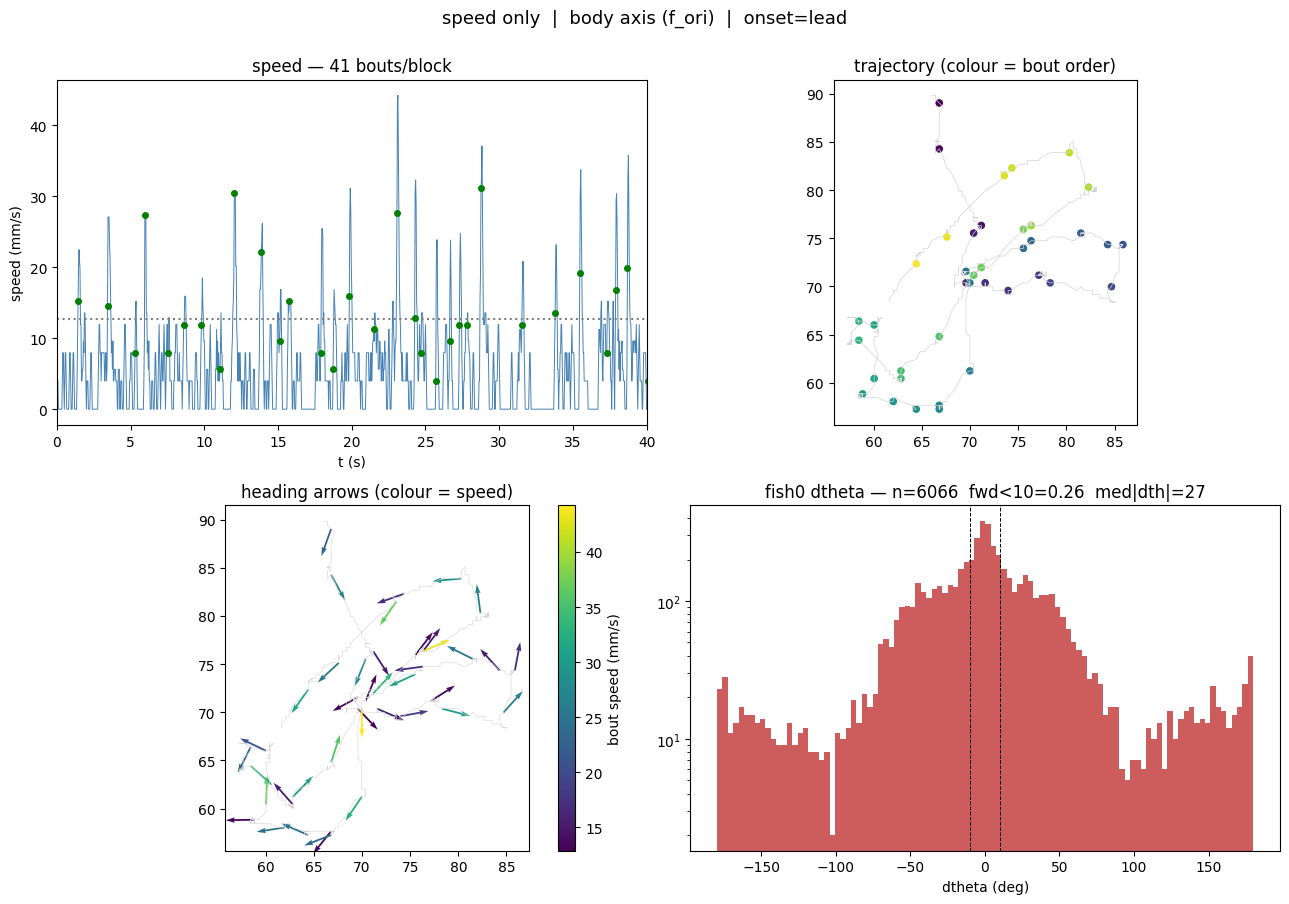

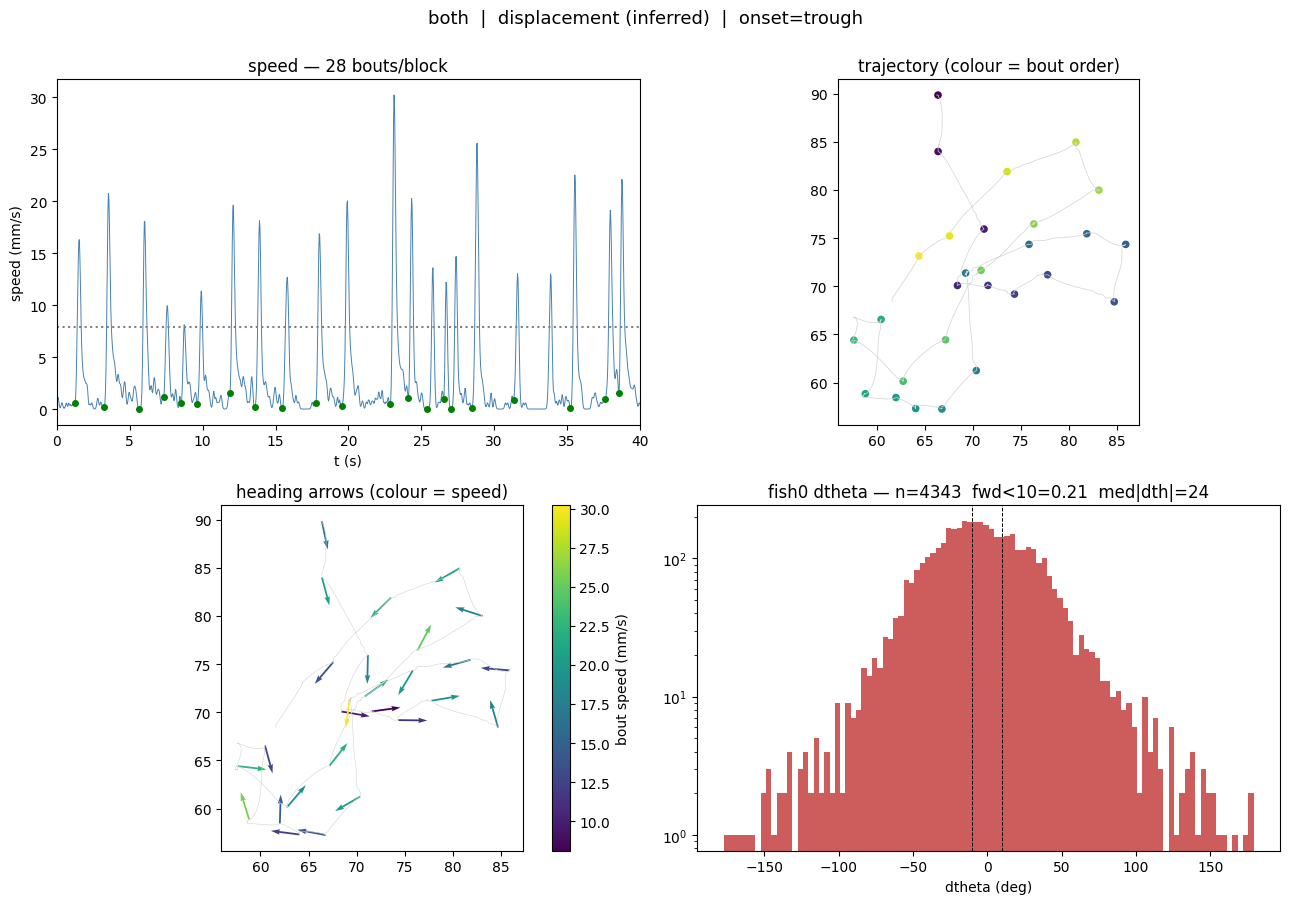

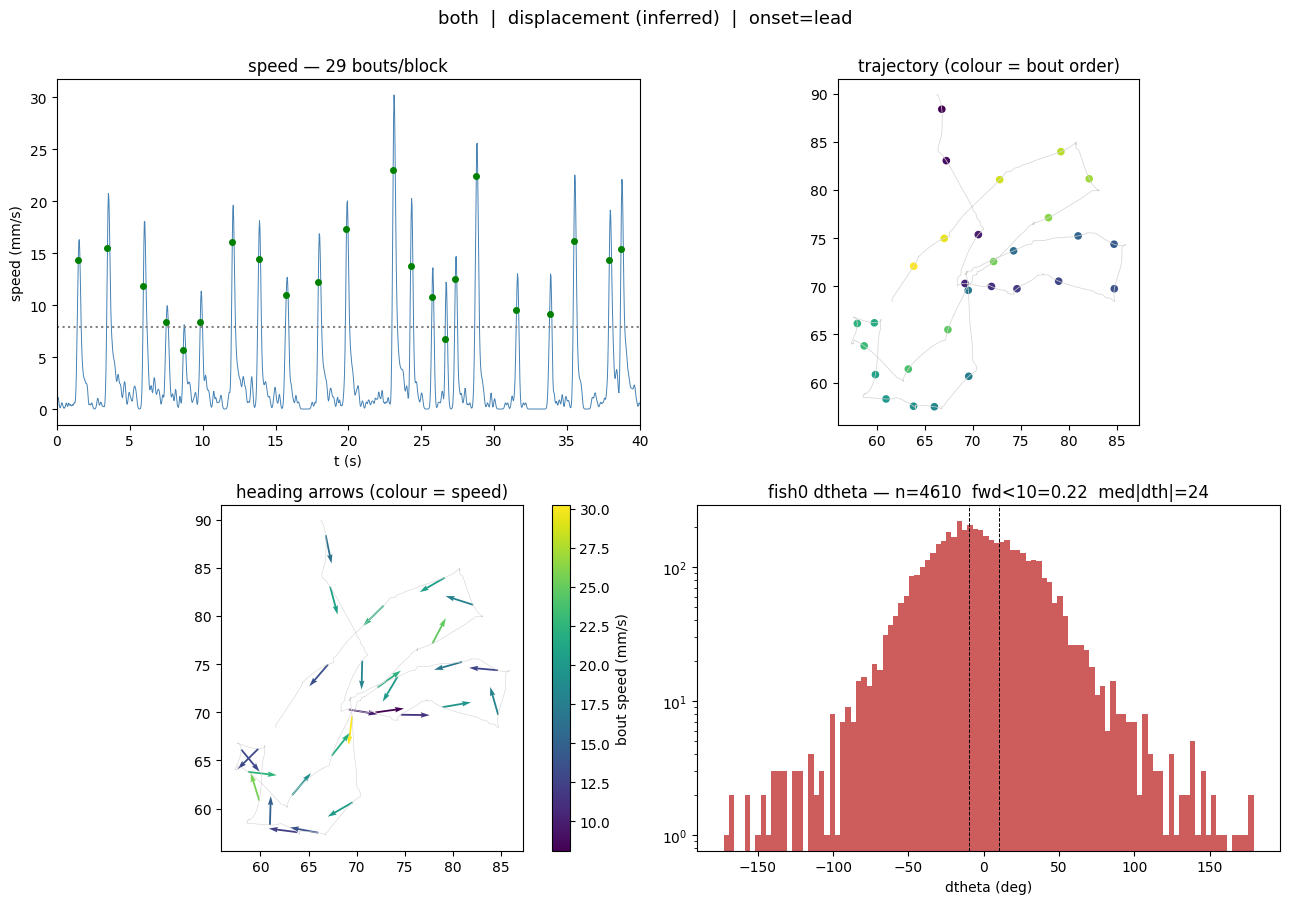

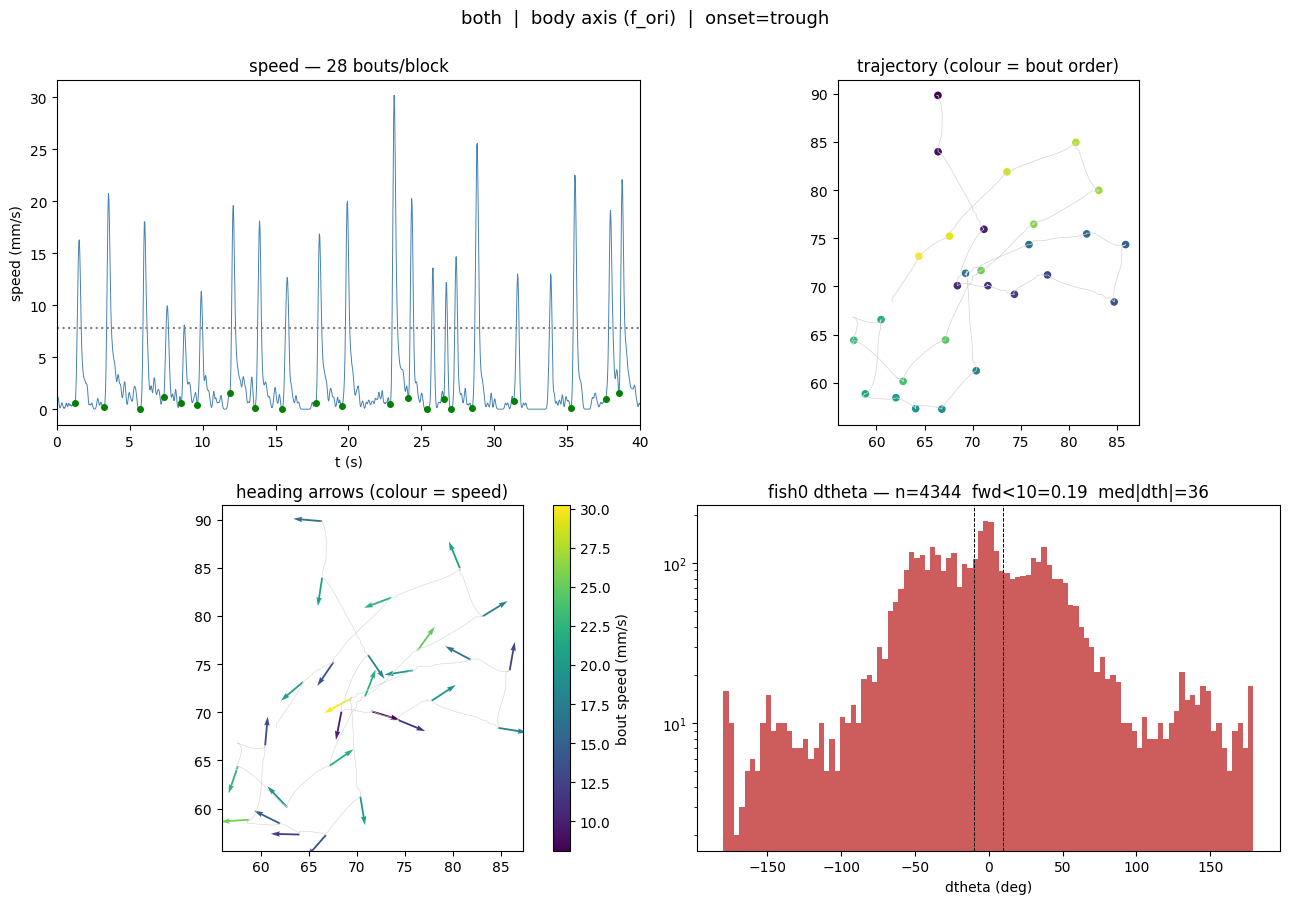

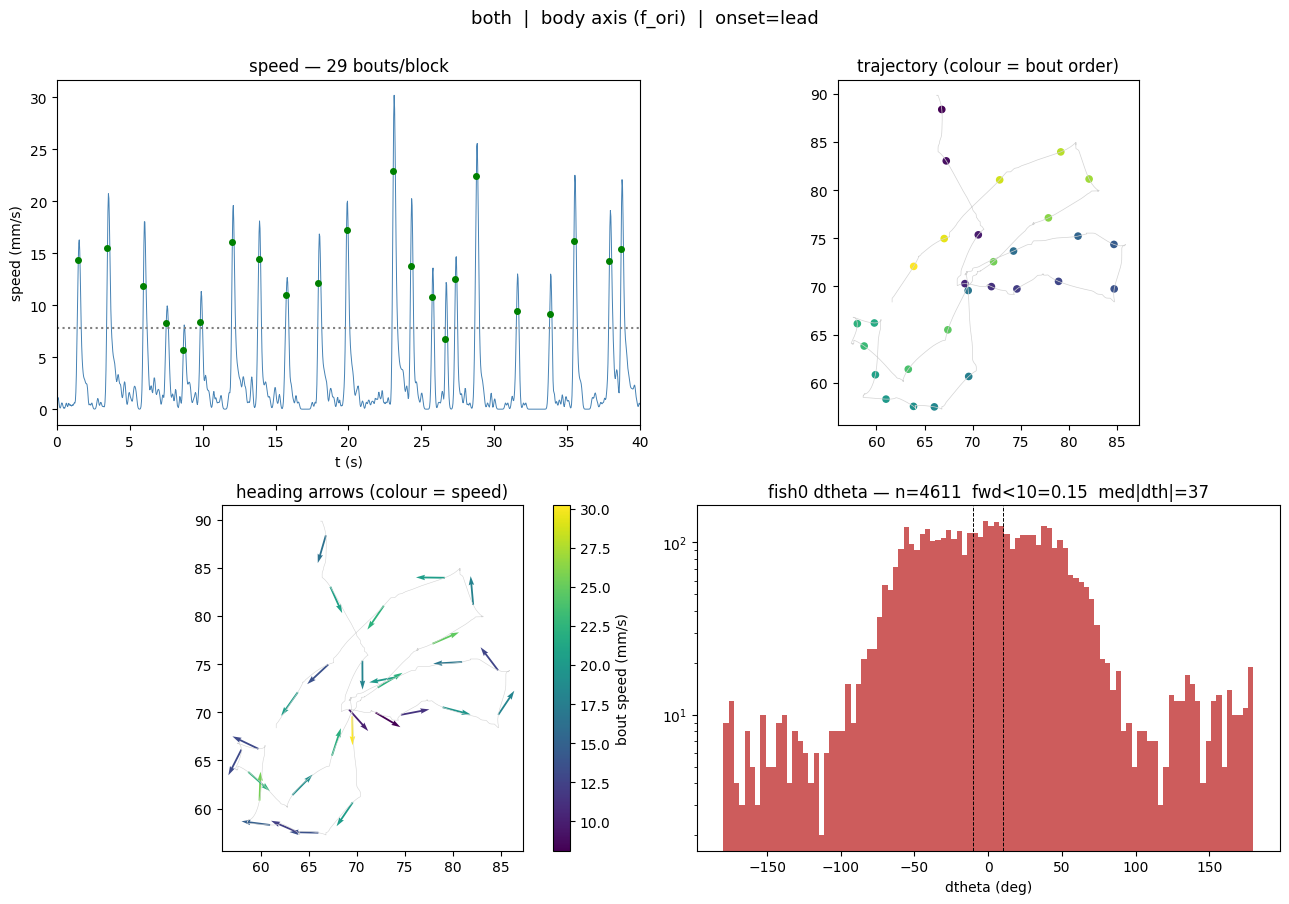

In [7]:
def show_variant(opts):
    b = block_for_plot(seg0, prefix0, scale0, opts)
    x, y, v = b["x"], b["y"], b["v"]
    on, theta, bs = b["onsets"], b["theta"], b["bout_speed"]
    sdth, _ = kin_for_fish(df0, prefix0, scale0, opts)   # fish-0 dtheta (all bouts)
    ad = np.abs(sdth)

    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle(opts["name"], fontsize=13, y=1.0)
    # (0,0) speed trace
    tt = np.arange(len(v)) / FPS
    a = ax[0, 0]; a.plot(tt, v, lw=0.7, color="steelblue")
    a.axhline(np.nanmean(v) + K * np.nanstd(v), color="gray", ls=":")
    a.plot(on / FPS, v[on], "o", color="green", ms=4)
    a.set_xlim(0, 40); a.set_xlabel("t (s)"); a.set_ylabel("speed (mm/s)")
    a.set_title(f"speed — {len(on)} bouts/block")
    # (0,1) trajectory by order
    a = ax[0, 1]; a.plot(x, y, lw=0.5, color="lightgray")
    a.scatter(x[on], y[on], c=np.arange(len(on)), cmap="viridis", s=20)
    a.set_aspect("equal"); a.set_title("trajectory (colour = bout order)")
    # (1,0) heading arrows coloured by speed
    a = ax[1, 0]; a.plot(x, y, lw=0.4, color="lightgray")
    msk = np.isfinite(theta); L = 3.0
    q = a.quiver(x[on][msk], y[on][msk], L * np.cos(theta[msk]), L * np.sin(theta[msk]),
                 bs[msk], angles="xy", scale_units="xy", scale=1, cmap="viridis", width=0.006)
    fig.colorbar(q, ax=a, label="bout speed (mm/s)")
    a.set_aspect("equal"); a.set_title("heading arrows (colour = speed)")
    # (1,1) dtheta histogram
    a = ax[1, 1]; a.hist(np.clip(sdth, -180, 180), bins=100, color="indianred")
    a.axvline(10, color="k", ls="--", lw=0.7); a.axvline(-10, color="k", ls="--", lw=0.7)
    a.set_yscale("log"); a.set_xlabel("dtheta (deg)")
    a.set_title(f"fish0 dtheta — n={len(sdth)}  fwd<10={(ad < 10).mean():.2f}  med|dth|={np.median(ad):.0f}")
    plt.tight_layout(); plt.show()


for opts in VARIANTS:
    show_variant(opts)

## 4. Summary table — all variants, all 15 fish

Quantitative ranking. **Read it together with `n` and `rate`:** a high forward fraction with a very large `n` / high rate usually means *over-detection* (spurious near-0 bouts), not a better heading — so don't pick on forward fraction alone.

In [8]:
acc = {v["name"]: dict(sdth=[], dt=[]) for v in VARIANTS}
for path in csvs:                       # read each file once; run all variants on it
    fid = int(re.search(r"_f(\d+)_transformed_abs", path.name).group(1))
    dfi = pd.read_csv(path); pref = f"f{fid}"; sc = scale_by_fish[fid]
    for v in VARIANTS:
        s, dt = kin_for_fish(dfi, pref, sc, v)
        acc[v["name"]]["sdth"] += list(s); acc[v["name"]]["dt"] += list(dt)

rows = []
for name, d in acc.items():
    s = np.abs(np.array(d["sdth"])); dt = np.array(d["dt"])
    rows.append(dict(variant=name, n_bouts=len(s),
                     rate_Hz=round(1 / np.median(dt), 2),
                     med_abs_dtheta=round(np.median(s), 1),
                     forward_frac=round((s < 10).mean(), 3)))
tab = pd.DataFrame(rows).sort_values("med_abs_dtheta").reset_index(drop=True)
display(tab)

,variant,n_bouts,rate_Hz,med_abs_dtheta,forward_frac
0,raw | body axis (f_ori) | onset=trough,110833,1.07,20.9,0.374
1,raw | body axis (f_ori) | onset=lead,111893,1.07,22.1,0.323
2,gaussian only | displacement (inferred) | ...,72615,0.81,25.2,0.220
3,both | displacement (inferred) | onset=lead,71798,0.81,25.2,0.220
4,gaussian only | displacement (inferred) | ...,71620,0.81,25.3,0.219
5,both | displacement (inferred) | onset=trough,70771,0.81,25.4,0.219
6,raw | displacement (inferred) | onset=lead,111878,1.07,25.9,0.224
7,raw | displacement (inferred) | onset=trough,110818,1.07,26.1,0.223
8,speed only | displacement (inferred) | ons...,93176,0.91,26.6,0.213
9,speed only | displacement (inferred) | ons...,94595,0.91,26.6,0.213


## 5. How to read this

- **Speed panel** → did smoothing tame the baseline? Fewer spurious detections is better; the `n_bouts`/`rate` columns quantify it. (This is the *only* place position smoothing shows up — everything else is drawn raw.)
- **Arrow panel** → the direct test of heading, over the **raw** path: arrows should run **along the path**. Body-axis variants show arrows pointing **against** the path at the 180° flips.
- **δθ histogram** → a single sharp peak at 0 (forward-dominated) is good; **lobes at ±180°** = head/tail flips; a flat/broad shape = noisy heading.
- **Don't trust `forward_frac` alone** — over-detection (large `n`) inflates it. Cross-check with the plots.

The configuration used by the main pipeline is **`both | displacement onset->onset (pipeline) | onset=trough`** — smoothing (both position and speed) is used **only to detect the bouts**, and heading is measured **onset-to-onset on the raw positions**, so the `onset` axis also shapes the heading. The `displacement peak->peak (old)` rows are the previous peak-anchored heading, kept for comparison; the `onset=lead` rows are the Le Goc-literal timing for reference.

**Tradeoff to notice in the table:** onset→onset displacement lands with a *higher* med|δθ| and *lower* forward fraction than peak→peak — close to the body-axis stats. Peak→peak avoids rest-point position noise (cleaner, more forward-peaked) but each arrow starts mid-bout; onset→onset guarantees every arrow points to the next bout but is more sensitive to integer-pixel jitter at the rest points. The onset→onset choice is deliberate — measuring the true direction from bout to bout, not smoothing the numbers into a prettier distribution — and the arrow panels (§2b) are the visual tiebreaker.